# 20 - Symptom text with the deployed ensemble: which way of combining, if any?

**Why:** in notebook 18b, late fusion with BERT left the field-photo accuracy unchanged
(98.9%) and lowered PlantDoc from 43.8% to 38.7%. That test differed from the app in four
ways: the crop was not given (so tomato and potato late blight, the same pathogen with
similar descriptions, competed), the text always counted as much as the photo, the image
scores were not calibrated, and only one encoder was tried. This notebook compares the
options the way the architectures were compared, and a rule fixed in advance chooses.

**Options compared (96, plus the photo alone):**

| What varies | Options |
|---|---|
| Text encoder | tfidf, minilm, distilbert, bert_base, mpnet, scibert |
| Which diseases the text may re-rank | only those of the farmer's crop (the app), or all 8 (notebook 11) |
| Text weight | 0.25, 0.5, 0.75, 1.0 |
| When the text acts | always, or only when the photo's confidence is below the 0.8 threshold |

Every option uses the deployed ensemble's calibrated probabilities (T from notebook 18b),
with the crop given, as in the app. Healthy classes are never changed by the text.

**Sentences:** the 64 train and val sentences are split into 4 folds (stratified by
disease); each sentence is scored by a text classifier trained without it, so every disease
has unseen sentences for the choice. The 8 test sentences are locked for the report only.

**Measured on the selection set (new field sources), each photo paired 5 times at random:**
- *help*: accuracy gain (crop given) when the sentence describes the right disease;
- *harm*: share of photos the image got right that turn wrong when the sentence describes
  another disease of the same crop (a farmer describing the wrong thing; for healthy
  photos, any disease of the crop);
- accuracy of the answers the app gives at the 0.8 threshold, with right and wrong text.

**Rule, fixed before running:**
1. Keep only options with harm <= 2% and, with wrong text, accuracy of answered photos at
   0.8 of at least 90% (the original promise; an option that answers nothing passes).
2. Of those, the largest help, if its paired bootstrap range lies entirely above zero.
3. Tied options (help at least the best's lower bound) go to the smaller encoder, then the
   lower weight, then "below 0.8" over "always", then "farmer's crop" over "all 8".
4. If no option passes, the photo alone stays, and the text stays an aid for the officer.

**Reported only (never used to choose):** text-only accuracy of each encoder; the test sets
and PlantDoc with the locked test sentences; the notebook 18b setup (no crop given,
uncalibrated, all 8, weight 1) beside the app setup; raw against calibrated image scores;
CPU time per sentence on the backend.

**Limitation stated up front:** these are factsheet sentences, not farmers' own words, and
three diseases (common rust, northern leaf blight, potato early blight) have no test
sentence. The result answers "if a farmer's words match a factsheet's, does it help?".

Runs on CPU; about 20-30 minutes, mostly downloading the five language models.

In [1]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount("/content/drive")

REPO_URL = "https://github.com/BilliartMuthoni/confidence-calibrated-crop-diagnosis.git"
REPO_DIR = Path("/content/drive/MyDrive/Sproutly-app")

if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}

ML_DIR = REPO_DIR / "ml"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config

Mounted at /content/drive


In [2]:
!git -C {REPO_DIR} config core.fileMode false
!git -C {REPO_DIR} pull --ff-only
!git -C {REPO_DIR} status --short --branch

Already up to date.
Refresh index: 100% (429/429), done.
## main...origin/main
 M ml/notebooks/20_symptom_fusion_comparison.ipynb
?? ml/results/fusion_quick_test/


In [3]:
%pip install -q -r {ML_DIR}/requirements.txt

## Settings, the ensemble's calibrated probabilities and the sentences

In [4]:
import importlib
import json
import shutil

import numpy as np
import pandas as pd
import torch

from src import calibration as cal, fusion, metrics, text_encoders, training
for module in (cal, fusion, metrics, text_encoders, training):
    importlib.reload(module)

SEED = config.RANDOM_SEED
THRESHOLD = 0.8                      # the deployed threshold (policy chosen after notebook 18b)
HARM_LIMIT, ANSWERED_TARGET = 0.02, 0.90
WEIGHTS = (0.25, 0.5, 0.75, 1.0)
SCOPES = ("crop", "all8")
GATES = ("always", "below 0.8")
ENCODERS = list(text_encoders.ENCODERS)
SIZE = {"tfidf": 0, "minilm": 22, "distilbert": 66, "bert_base": 110, "mpnet": 110, "scibert": 110}  # million weights
PAIRINGS, FOLDS, BOOTSTRAP = 5, 4, 1000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

N18B = ML_DIR / "results" / "ensemble_deployment" / "calibrator_final.json"
deployed = json.loads(N18B.read_text())
MEMBERS, TEMPERATURE = deployed["model_runs"], deployed["temperature"]
assert MEMBERS == ["d17_resnet50_seed44", "d22_convnext_tiny_lr1e-04", "d22_efficientnet_b0"], MEMBERS
FOLDER = {"d17": config.MODELS_DIR / "d17_comparison", "d22": config.MODELS_DIR / "d22_comparison"}
OUT_DIR = config.MODELS_DIR / "fusion_d20"
REPO_RESULTS = ML_DIR / "results" / "fusion_d20"
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPO_RESULTS.mkdir(parents=True, exist_ok=True)

SETS = ["selection", "test", "ood_test"]
CLASSES = list(config.PLANTVILLAGE_CLASSES)
INDEX = {name: i for i, name in enumerate(CLASSES)}
CLASS_CROPS = np.array([{"Corn_(maize)": "maize", "Tomato": "tomato", "Potato": "potato"}[c.split("___")[0]]
                        for c in CLASSES])
SHORT = {c: c.replace("Corn_(maize)___", "Maize ").replace("___", " ").replace("_", " ").strip() for c in CLASSES}
DISEASE = np.flatnonzero(~fusion.healthy_mask(CLASSES))            # the 8 disease classes, in text-classifier order
HEALTHY = fusion.healthy_mask(CLASSES)
FIELD_SOURCES = ["fieldplant", "tanzania"]

PARTS = {}
for name in SETS:
    rows = pd.read_csv(config.SPLITS_DIR / f"{name}.csv")
    labels = rows["class"].map(INDEX)
    keep = labels.notna().to_numpy()
    lab = labels[keep].astype(int).to_numpy()
    members = [np.load(FOLDER[m[:3]] / f"{m}__{name}.npy")[keep] for m in MEMBERS]
    raw = np.log(np.mean([metrics.softmax(s) for s in members], axis=0) + 1e-12)   # the backend's combination
    PARTS[name] = {"rows": rows[keep].reset_index(drop=True), "labels": lab, "crops": CLASS_CROPS[lab], "raw": raw}
# The temperature was fitted on the selection set, so there each photo is calibrated without itself (as in 18b).
sel = PARTS["selection"]
sel["probs"] = cal.out_of_fold("temperature", sel["raw"], sel["labels"], 5, SEED)
for name in ["test", "ood_test"]:
    PARTS[name]["probs"] = cal.Calibrator("temperature", {"temperature": TEMPERATURE}).probabilities(PARTS[name]["raw"])
FIELD_TEST = PARTS["test"]["rows"]["source"].isin(FIELD_SOURCES).to_numpy()

descriptions = pd.read_csv(ML_DIR / "data" / "symptoms" / "descriptions.csv", encoding="utf-8-sig")
descriptions = descriptions[descriptions["keep"] == "y"].reset_index(drop=True)
descriptions["label"] = descriptions["class_name"].map(INDEX)
descriptions["disease"] = descriptions["label"].map({c: i for i, c in enumerate(DISEASE)})
pool = descriptions[descriptions["split"].isin(["train", "val"])].reset_index(drop=True)
locked = descriptions[descriptions["split"] == "test"].reset_index(drop=True)
rng = np.random.default_rng(SEED)
pool["fold"] = -1
for _, group in pool.groupby("disease"):
    order = rng.permutation(group.index.to_numpy())
    pool.loc[order, "fold"] = np.arange(len(order)) % FOLDS
print(f"Ensemble T = {TEMPERATURE:.4f}; photos: " + ", ".join(f"{n} {len(PARTS[n]['labels'])}" for n in SETS))
print("Sentences per disease (pool for choosing / locked test):")
display(pd.DataFrame({"pool": pool["class_name"].map(SHORT).value_counts(),
                      "test": locked["class_name"].map(SHORT).value_counts()}).fillna(0).astype(int))

Ensemble T = 2.4381; photos: selection 3821, test 2441, ood_test 953
Sentences per disease (pool for choosing / locked test):


,pool,test
class_name,,
Maize Cercospora leaf spot Gray leaf spot,5,1
Maize Common rust,5,0
Maize Northern Leaf Blight,4,0
Potato Early blight,4,0
Potato Late blight,19,2
Tomato Bacterial spot,9,2
Tomato Early blight,11,1
Tomato Late blight,7,2


## Text classifiers: out-of-fold scores for the pool, and the final one for the test sentences

The text classifier is the notebook 11 late-fusion head (one linear layer over the 8
diseases on frozen sentence vectors). TF-IDF's vocabulary is refitted inside each fold so
an unseen sentence never shapes it.

In [5]:
def text_classifier(vectors, diseases, seed=SEED):
    bank = fusion.TextBank({int(DISEASE[d]): vectors[diseases == d] for d in np.unique(diseases)}, vectors.shape[1])
    return fusion.train_head("late", None, None, bank, None, CLASSES, 0.0, seed, DEVICE)


@torch.no_grad()
def log_probs(head, vectors):
    return torch.log_softmax(head(torch.as_tensor(vectors, dtype=torch.float32, device=DEVICE)), 1).cpu().numpy()


TEXT = {}          # encoder -> {"pool": out-of-fold log-probs (64, 8), "test": final classifier on test sentences (8, 8)}
HEADS = {}
for encoder in ENCODERS:
    texts = pool["text"].tolist()
    oof = np.zeros((len(pool), len(DISEASE)))
    if encoder != "tfidf":
        frozen = text_encoders.encode(encoder, texts + locked["text"].tolist(), texts, DEVICE)
    for k in range(FOLDS):
        fit_on, held = (pool["fold"] != k).to_numpy(), (pool["fold"] == k).to_numpy()
        if encoder == "tfidf":
            vectors = text_encoders.encode("tfidf", texts, [t for t, f in zip(texts, fit_on) if f])
        else:
            vectors = frozen[:len(pool)]
        head = text_classifier(vectors[fit_on], pool["disease"].to_numpy()[fit_on])
        oof[held] = log_probs(head, vectors[held])
    if encoder == "tfidf":
        everything = text_encoders.encode("tfidf", texts + locked["text"].tolist(), texts)
    else:
        everything = frozen
    HEADS[encoder] = text_classifier(everything[:len(pool)], pool["disease"].to_numpy())
    TEXT[encoder] = {"pool": oof, "test": log_probs(HEADS[encoder], everything[len(pool):])}
    print(f"{encoder}: done")


def text_only(lp, sentences):
    truth = sentences["disease"].to_numpy()
    crops = CLASS_CROPS[DISEASE][truth]
    in_crop = np.where(CLASS_CROPS[DISEASE][None, :] == crops[:, None], lp, -np.inf)
    return (lp.argmax(1) == truth).mean(), (in_crop.argmax(1) == truth).mean()


text_rows = []
for encoder in ENCODERS:
    a8, ac = text_only(TEXT[encoder]["pool"], pool)
    t8, tc = text_only(TEXT[encoder]["test"], locked)
    text_rows.append({"encoder": encoder, "pool out-of-fold: 8-way": a8, "pool out-of-fold: crop given": ac,
                      "test: 8-way": t8, "test: crop given": tc})
text_table = pd.DataFrame(text_rows).set_index("encoder")
print("Text alone, share of sentences whose disease is named correctly (reported only):")
display(text_table.round(3))

tfidf: done


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


scibert: done
Text alone, share of sentences whose disease is named correctly (reported only):


,pool out-of-fold: 8-way,pool out-of-fold: crop given,test: 8-way,test: crop given
encoder,,,,
tfidf,0.328,0.641,0.375,0.625
distilbert,0.312,0.562,0.375,0.625
bert_base,0.328,0.547,0.250,0.625
minilm,0.312,0.641,0.250,0.625
mpnet,0.312,0.609,0.375,0.625
scibert,0.359,0.641,0.500,0.625


## Pairing photos with sentences

Each diseased photo gets a random sentence of its own disease (right text) and, separately,
a random sentence of another disease of its crop (wrong text). Healthy photos get no right
text (no source describes healthy leaves) and, as wrong text, a sentence of any disease of
their crop. Photos whose class has no sentence in that set get no text.

In [6]:
def pairings(labels, sentences, wrong, seed):
    # Index of the paired sentence for each photo, -1 for none.
    rng = np.random.default_rng(seed)
    by_class = {c: g.index.to_numpy() for c, g in sentences.groupby("label")}
    sentence_crop = CLASS_CROPS[sentences["label"].to_numpy()]
    chosen = np.full(len(labels), -1)
    for i, label in enumerate(labels):
        if not wrong:
            options = by_class.get(int(label), [])
        else:
            options = np.flatnonzero((sentence_crop == CLASS_CROPS[label]) & (sentences["label"].to_numpy() != label))
        if len(options):
            chosen[i] = options[rng.integers(len(options))]
    return chosen


def fused(probs, crops, text_lp, chosen, weight, scope, gate):
    has = (chosen >= 0).astype(float)
    lp = np.where(has[:, None] > 0, text_lp[np.maximum(chosen, 0)], 0.0)
    return fusion.crop_fusion_probabilities(probs, lp, has, DISEASE, CLASS_CROPS, crops, weight,
                                            within_crop=scope == "crop", gate=THRESHOLD if gate == "below 0.8" else None)


def app(probs, crops, labels):
    conf, predicted = cal.crop_confidence(probs, CLASS_CROPS, crops)
    return conf, predicted == labels


PAIRS = {name: {kind: [pairings(PARTS[name]["labels"], pool if name == "selection" else locked, kind == "wrong", SEED + r)
                       for r in range(PAIRINGS)] for kind in ("right", "wrong")} for name in SETS}
print("Selection photos with right text:", f"{(PAIRS['selection']['right'][0] >= 0).mean():.1%}",
      "| with wrong text:", f"{(PAIRS['selection']['wrong'][0] >= 0).mean():.1%}")

Selection photos with right text: 57.8% | with wrong text: 100.0%


## All 96 options on the selection set

In [7]:
def evaluate(name, encoder, weight, scope, gate, mask=None, probs=None):
    part = PARTS[name]
    probs = part["probs"] if probs is None else probs
    labels, crops = part["labels"], part["crops"]
    m = np.ones(len(labels), bool) if mask is None else mask
    conf0, ok0 = app(probs[m], crops[m], labels[m])
    text_lp = TEXT[encoder]["pool" if name == "selection" else "test"]
    out = {}
    for kind in ("right", "wrong"):
        oks, answered, answered_ok = [], 0, 0
        for chosen in PAIRS[name][kind]:
            conf, ok = app(fused(probs[m], crops[m], text_lp, chosen[m], weight, scope, gate), crops[m], labels[m])
            oks.append(ok)
            answered += (conf >= THRESHOLD).sum()
            answered_ok += ((conf >= THRESHOLD) & ok).sum()
        out[kind] = {"ok": np.mean(oks, axis=0), "answered": answered / (PAIRINGS * m.sum()),
                     "accuracy of answered": answered_ok / answered if answered else np.nan}
    healthy = HEALTHY[labels[m]]
    wrong_share = 1 - out["wrong"]["ok"]
    return {"photos": int(m.sum()), "accuracy image": ok0.mean(), "accuracy right text": out["right"]["ok"].mean(),
            "help": out["right"]["ok"].mean() - ok0.mean(),
            "harm": wrong_share[ok0].mean() if ok0.any() else np.nan,
            "harm (diseased photos)": wrong_share[ok0 & ~healthy].mean() if (ok0 & ~healthy).any() else np.nan,
            "harm (healthy photos)": wrong_share[ok0 & healthy].mean() if (ok0 & healthy).any() else np.nan,
            "answered image": (conf0 >= THRESHOLD).mean(),
            "accuracy of answered image": ok0[conf0 >= THRESHOLD].mean() if (conf0 >= THRESHOLD).any() else np.nan,
            "answered right text": out["right"]["answered"], "accuracy of answered right text": out["right"]["accuracy of answered"],
            "answered wrong text": out["wrong"]["answered"], "accuracy of answered wrong text": out["wrong"]["accuracy of answered"],
            "_diff": out["right"]["ok"] - ok0}


resample = np.random.default_rng(SEED).integers(0, len(sel["labels"]), (BOOTSTRAP, len(sel["labels"])))  # paired: same photos for all
rows = []
for encoder in ENCODERS:
    for scope in SCOPES:
        for weight in WEIGHTS:
            for gate in GATES:
                r = evaluate("selection", encoder, weight, scope, gate)
                low, high = np.percentile(r.pop("_diff")[resample].mean(axis=1), [2.5, 97.5])
                rows.append({"encoder": encoder, "scope": scope, "weight": weight, "gate": gate,
                             **r, "help low": low, "help high": high})
options = pd.DataFrame(rows)
print(len(options), "options evaluated")

96 options evaluated


## The rule

In [8]:
options["safe"] = (options["harm"] <= HARM_LIMIT) & (options["accuracy of answered wrong text"].fillna(1.0) >= ANSWERED_TARGET)
options["helps"] = options["help low"] > 0
options["passes"] = options["safe"] & options["helps"]
options["order"] = list(zip(options["encoder"].map(SIZE), options["encoder"], options["weight"],
                            options["gate"] != "below 0.8", options["scope"] != "crop"))
passing = options[options["passes"]]
if len(passing):
    best = passing.loc[passing["help"].idxmax()]
    tied = passing[passing["help"] >= best["help low"]]
    winner = tied.loc[min(tied.index, key=lambda i: tied.at[i, "order"])]
    WINNER = {"encoder": winner["encoder"], "scope": winner["scope"], "weight": float(winner["weight"]),
              "gate": winner["gate"]}
    VERDICT = (f"Text fusion is used: {WINNER} (help {winner['help']:+.3f}, range {winner['help low']:+.3f} to "
               f"{winner['help high']:+.3f}; harm {winner['harm']:.3f}; {len(tied)} option(s) tied with the best)")
else:
    WINNER = None
    VERDICT = (f"No option passes ({int(options['safe'].sum())} safe, {int(options['helps'].sum())} help beyond the range, "
               "none both): the photo alone stays and the text stays an aid for the officer")
print(VERDICT)

view = ["encoder", "scope", "weight", "gate", "help", "help low", "help high", "harm", "harm (healthy photos)",
        "answered right text", "accuracy of answered right text", "accuracy of answered wrong text", "passes"]
print("\nAll options, largest help first:")
display(options.sort_values("help", ascending=False)[view].round(3).to_string(index=False))
print("\nBest option of each encoder (largest help among its safe options; reported only):")
safe = options[options["safe"]]
display(safe.loc[safe.groupby("encoder")["help"].idxmax()][view].round(3).to_string(index=False) if len(safe) else "none safe")
image_only = options.iloc[0][["accuracy image", "answered image", "accuracy of answered image"]]
print("\nPhoto alone on the selection set:", image_only.round(3).to_dict())

Text fusion is used: {'encoder': 'tfidf', 'scope': 'crop', 'weight': 0.25, 'gate': 'below 0.8'} (help +0.007, range +0.005 to +0.010; harm 0.010; 4 option(s) tied with the best)

All options, largest help first:


'   encoder scope  weight      gate   help  help low  help high  harm  harm (healthy photos)  answered right text  accuracy of answered right text  accuracy of answered wrong text  passes\ndistilbert  crop    0.50    always  0.035     0.027      0.043 0.135                  0.033                0.226                            0.995                            0.994   False\ndistilbert  crop    0.50 below 0.8  0.035     0.027      0.043 0.135                  0.033                0.228                            0.995                            0.994   False\ndistilbert  crop    0.75 below 0.8  0.032     0.023      0.041 0.183                  0.047                0.241                            0.993                            0.980   False\ndistilbert  crop    0.75    always  0.032     0.023      0.041 0.184                  0.047                0.237                            0.993                            0.979   False\ndistilbert  all8    0.50 below 0.8  0.030     0.022      0.


Best option of each encoder (largest help among its safe options; reported only):


'encoder scope  weight   gate  help  help low  help high  harm  harm (healthy photos)  answered right text  accuracy of answered right text  accuracy of answered wrong text  passes\n  tfidf  crop    0.25 always 0.007     0.005       0.01  0.01                  0.001                0.209                            0.995                            0.995    True'


Photo alone on the selection set: {'accuracy image': 0.7458780423972782, 'answered image': 0.2088458518712379, 'accuracy of answered image': 0.9949874686716792}


## Help against harm, every option

Each point is one option; the dashed line is the 2% harm limit. Filled points pass the rule.

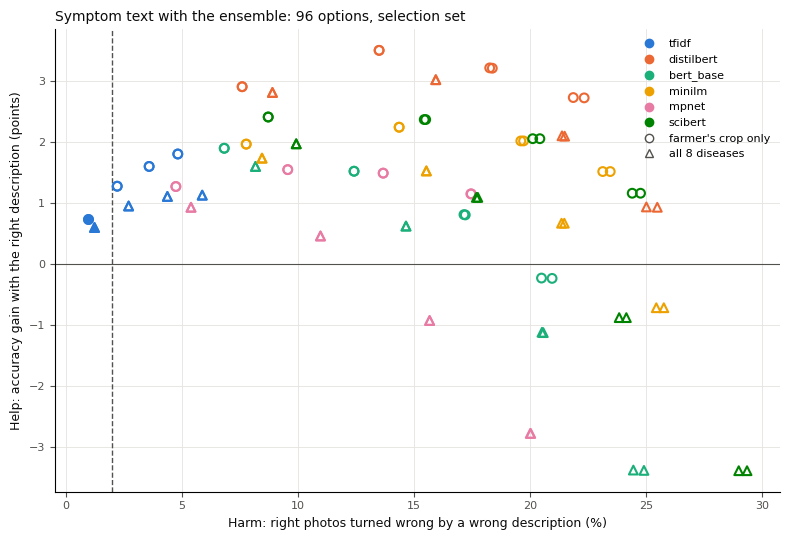

In [9]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed order, one per encoder
COLOR = dict(zip(ENCODERS, SERIES))
MARKER = {"crop": "o", "all8": "^"}

fig, ax = plt.subplots(figsize=(8, 5.5))
for _, r in options.iterrows():
    ax.scatter(r["harm"] * 100, r["help"] * 100, s=40, marker=MARKER[r["scope"]], linewidths=1.5,
               facecolors=COLOR[r["encoder"]] if r["passes"] else "none", edgecolors=COLOR[r["encoder"]], zorder=3)
ax.axvline(HARM_LIMIT * 100, color=MUTED, linestyle="--", linewidth=1)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.grid(color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_xlabel("Harm: right photos turned wrong by a wrong description (%)", color=INK, fontsize=9)
ax.set_ylabel("Help: accuracy gain with the right description (points)", color=INK, fontsize=9)
ax.set_title("Symptom text with the ensemble: 96 options, selection set", color=INK, fontsize=10, loc="left")
ax.tick_params(colors=MUTED, labelsize=8)
handles = [Line2D([], [], marker="o", linestyle="", color=COLOR[e], label=e) for e in ENCODERS]
handles += [Line2D([], [], marker=MARKER[s], linestyle="", color=MUTED, markerfacecolor="none",
                   label={"crop": "farmer's crop only", "all8": "all 8 diseases"}[s]) for s in SCOPES]
ax.legend(handles=handles, fontsize=8, frameon=False, loc="best")
plt.tight_layout()
plt.savefig(OUT_DIR / "help_vs_harm.png", dpi=150)
plt.show()

## Reported only: the locked test sentences, PlantDoc, and the notebook 18b setup

Each row is one option on one set. "No crop given" is how notebook 18b measured: the best
of all 11 classes, not of the farmer's crop. The rows show how much of 18b's PlantDoc drop
came from that test design rather than from the text.

In [10]:
def no_crop(probs, labels):
    return (probs.argmax(1) == labels).mean()


REPORTED = {"winner": WINNER} if WINNER else {}
for encoder in ENCODERS:
    pick = safe[safe["encoder"] == encoder]
    if len(pick):
        best_of = pick.loc[pick["help"].idxmax()]
        REPORTED[f"best safe {encoder}"] = {k: best_of[k] for k in ("encoder", "scope", "weight", "gate")}
OLD = {"encoder": "bert_base", "scope": "all8", "weight": 1.0, "gate": "always"}

report = []
for label, name, mask in [("test", "test", None), ("test: field photos", "test", FIELD_TEST), ("PlantDoc", "ood_test", None)]:
    part = PARTS[name]
    m = np.ones(len(part["labels"]), bool) if mask is None else mask
    for option_name, option in [*REPORTED.items(), ("notebook 18b setup", OLD)]:
        raw_scores = option_name == "notebook 18b setup"
        probs = metrics.softmax(part["raw"]) if raw_scores else part["probs"]
        r = evaluate(name, **option, mask=m, probs=probs)
        r.pop("_diff")
        chosen = PAIRS[name]["right"][0][m]
        text_lp = TEXT[option["encoder"]]["test"]
        report.append({"set": label, "option": option_name, **option, "image scores": "raw" if raw_scores else "calibrated",
                       "accuracy image (crop given)": r["accuracy image"], "accuracy right text (crop given)": r["accuracy right text"],
                       "accuracy image (no crop given)": no_crop(probs[m], part["labels"][m]),
                       "accuracy right text (no crop given)": no_crop(fused(probs[m], part["crops"][m], text_lp, chosen,
                                                                          **{k: option[k] for k in ("weight", "scope", "gate")}),
                                                                    part["labels"][m]),
                       "harm": r["harm"], "accuracy of answered image": r["accuracy of answered image"],
                       "accuracy of answered right text": r["accuracy of answered right text"],
                       "accuracy of answered wrong text": r["accuracy of answered wrong text"],
                       "photos with right text": (chosen >= 0).mean()})
report_table = pd.DataFrame(report)
display(report_table.round(3).to_string(index=False))
print("Classes with no test sentence (their photos get no text above):",
      sorted(SHORT[CLASSES[c]] for c in DISEASE if c not in set(locked["label"])))

'               set             option   encoder scope  weight      gate image scores  accuracy image (crop given)  accuracy right text (crop given)  accuracy image (no crop given)  accuracy right text (no crop given)  harm  accuracy of answered image  accuracy of answered right text  accuracy of answered wrong text  photos with right text\n              test             winner     tfidf  crop    0.25 below 0.8   calibrated                        0.995                             0.995                           0.995                                0.995 0.000                       0.999                            0.999                            0.999                   0.489\n              test    best safe tfidf     tfidf  crop    0.25    always   calibrated                        0.995                             0.995                           0.995                                0.995 0.000                       0.999                            0.999                            0.99

Classes with no test sentence (their photos get no text above): ['Maize Common rust', 'Maize Northern Leaf Blight', 'Potato Early blight']


In [11]:
# Raw against calibrated image scores for the chosen option (or BERT, crop only, weight 1, always): reported only.
check = WINNER or {"encoder": "bert_base", "scope": "crop", "weight": 1.0, "gate": "always"}
raw_rows = []
for scores in ("calibrated", "raw"):
    probs = sel["probs"] if scores == "calibrated" else metrics.softmax(sel["raw"])
    r = evaluate("selection", **check, probs=probs)
    r.pop("_diff")
    raw_rows.append({"image scores": scores, **{k: r[k] for k in ("accuracy image", "help", "harm",
                     "answered right text", "accuracy of answered right text", "accuracy of answered wrong text")}})
raw_table = pd.DataFrame(raw_rows).set_index("image scores")
print("Option:", check)
display(raw_table.round(3))

# Per disease on the selection set for the same option (reported only).
per_class = []
for c in np.unique(sel["labels"]):
    m = sel["labels"] == c
    r = evaluate("selection", **check, mask=m)
    r.pop("_diff")
    per_class.append({"class": SHORT[CLASSES[c]], "photos": int(m.sum()), "accuracy image": r["accuracy image"],
                      "accuracy right text": r["accuracy right text"], "harm": r["harm"]})
per_class_table = pd.DataFrame(per_class).set_index("class")
display(per_class_table.round(3))

cpu_ms = {e: text_encoders.cpu_milliseconds_per_sentence(e, pool["text"].iloc[0]) for e in ENCODERS}
print("CPU milliseconds per sentence (2 threads, as on the backend):", {k: round(v, 1) for k, v in cpu_ms.items()})

Option: {'encoder': 'tfidf', 'scope': 'crop', 'weight': 0.25, 'gate': 'below 0.8'}


,accuracy image,help,harm,answered right text,accuracy of answered right text,accuracy of answered wrong text
image scores,,,,,,
calibrated,0.746,0.007,0.010,0.210,0.995,0.995
raw,0.746,0.004,0.004,0.411,0.960,0.960


,photos,accuracy image,accuracy right text,harm
class,,,,
Maize Cercospora leaf spot Gray leaf spot,1380,0.750,0.759,0.015
Maize Common rust,126,0.913,0.921,0.017
Maize healthy,961,0.947,0.947,0.000
Tomato Bacterial spot,97,0.247,0.245,0.083
Tomato Early blight,447,0.485,0.514,0.020
Tomato Late blight,92,0.457,0.483,0.062
Tomato healthy,307,0.319,0.319,0.008
Potato Late blight,67,1.000,1.000,0.000
Potato healthy,344,0.994,0.994,0.001


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CPU milliseconds per sentence (2 threads, as on the backend): {'tfidf': 0.0, 'distilbert': 73.8, 'bert_base': 369.3, 'minilm': 18.4, 'mpnet': 157.0, 'scibert': 581.5}


## Save the decision

In [12]:
decision = {"verdict": VERDICT, "winner": WINNER, "rule": {
                "harm_limit": HARM_LIMIT, "answered_target_with_wrong_text": ANSWERED_TARGET, "threshold": THRESHOLD,
                "help": "largest help whose paired bootstrap range lies above zero",
                "tie": "help at least the best's lower bound; then smaller encoder, lower weight, gated, farmer's crop"},
            "image_model": {"members": MEMBERS, "temperature": TEMPERATURE},
            "sentences": {"pool": len(pool), "folds": FOLDS, "locked_test": len(locked)},
            "pairings_per_photo": PAIRINGS, "selection_photos": int(len(sel["labels"])),
            "options_safe": int(options["safe"].sum()), "options_helping": int(options["helps"].sum()),
            "options_passing": int(options["passes"].sum()), "cpu_ms_per_sentence": cpu_ms}
training.save_json(decision, OUT_DIR / "decision.json")
options.drop(columns="order").to_csv(OUT_DIR / "options.csv", index=False)
text_table.to_csv(OUT_DIR / "text_only.csv")
report_table.to_csv(OUT_DIR / "report_sets.csv", index=False)
raw_table.to_csv(OUT_DIR / "raw_vs_calibrated.csv")
per_class_table.to_csv(OUT_DIR / "per_class.csv")
if WINNER:
    # The chosen text classifier, trained on all 64 pool sentences; not in Git (models are on Drive).
    torch.save(HEADS[WINNER["encoder"]].state_dict(), OUT_DIR / "text_head.pt")
    print("Saved the text classifier for", WINNER["encoder"], "to", OUT_DIR / "text_head.pt")
print(json.dumps(decision, indent=1, default=float))

Saved the text classifier for tfidf to /content/drive/MyDrive/CropDiseaseDiagnosis/models/fusion_d20/text_head.pt
{
 "verdict": "Text fusion is used: {'encoder': 'tfidf', 'scope': 'crop', 'weight': 0.25, 'gate': 'below 0.8'} (help +0.007, range +0.005 to +0.010; harm 0.010; 4 option(s) tied with the best)",
 "winner": {
  "encoder": "tfidf",
  "scope": "crop",
  "weight": 0.25,
  "gate": "below 0.8"
 },
 "rule": {
  "harm_limit": 0.02,
  "answered_target_with_wrong_text": 0.9,
  "threshold": 0.8,
  "help": "largest help whose paired bootstrap range lies above zero",
  "tie": "help at least the best's lower bound; then smaller encoder, lower weight, gated, farmer's crop"
 },
 "image_model": {
  "members": [
   "d17_resnet50_seed44",
   "d22_convnext_tiny_lr1e-04",
   "d22_efficientnet_b0"
  ],
  "temperature": 2.4381275602850097
 },
 "sentences": {
  "pool": 64,
  "folds": 4,
  "locked_test": 8
 },
 "pairings_per_photo": 5,
 "selection_photos": 3821,
 "options_safe": 4,
 "options_helpin

## Copy the results into the repository, sync Drive, save to GitHub

Save the notebook first (Ctrl+S).

In [13]:
for file in OUT_DIR.glob("*"):
    if file.suffix in {".csv", ".json", ".png"}:
        shutil.copy(file, REPO_RESULTS / file.name)
print(sorted(p.name for p in REPO_RESULTS.iterdir()))
drive.flush_and_unmount()
drive.mount("/content/drive")

['decision.json', 'help_vs_harm.png', 'options.csv', 'per_class.csv', 'raw_vs_calibrated.csv', 'report_sets.csv', 'text_only.csv']
Mounted at /content/drive


In [16]:
from google.colab import userdata

from src import github_sync

shutil.copy(ML_DIR / "notebooks" / "20_symptom_fusion_comparison.ipynb", REPO_RESULTS / "notebook.ipynb")
print(github_sync.push(
    REPO_DIR,
    branch="colab/fusion-comparison",
    message="Symptom text with the ensemble: 96 fusion options compared",
    token=userdata.get("GITHUB_TOKEN"),
    name="BilliartMuthoni",
    email=userdata.get("GIT_EMAIL"),
    paths=[str(REPO_RESULTS.relative_to(REPO_DIR))],
))

RuntimeError: fatal: a branch named 'colab/fusion-comparison' already exists

In [17]:
!git -C {REPO_DIR} log --oneline -1 colab/fusion-comparison
!git -C {REPO_DIR} branch -D colab/fusion-comparison
!git -C {REPO_DIR} status --short --branch


c04f1a2 (colab/fusion-comparison) Compare text encoders, fusion methods and missing-text rates
Deleted branch colab/fusion-comparison (was c04f1a2).
Refresh index: 100% (429/429), done.
## main...origin/main
 M ml/notebooks/20_symptom_fusion_comparison.ipynb
?? ml/results/fusion_d20/
?? ml/results/fusion_quick_test/
